In [ ]:
import matplotlib.pyplot as plt    
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'     #폰트
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False          #마이너스부호
import pandas as pd                  
import numpy as np                    
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split    
from sklearn.neighbors import KNeighborsClassifier

In [76]:
#도미-35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

#빙어-14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

length = bream_length + smelt_length
weight = bream_weight + smelt_weight

In [77]:
data= np.column_stack((length,weight))
label = [1]*35+[0]*14

In [78]:
data[0:2]

array([[ 25.4, 242. ],
       [ 26.3, 290. ]])

In [79]:
#데이터 전처리
# 표준점수 고려해야 함.
#표준점수 = (특성값 - 산술평균)/ 표준편차
mean = np.mean(data,axis=0) #행의 기준으로 산술평균
std = np.std(data,axis=0)   #행의 기준으로 표준편차
train_scaled = (data-mean)/std
new_data = ([25,150]-mean)/std
new_data2 = ([29.5,300]-mean)/std


In [80]:
#학습용.시험용 으로 나누기
train_data,test_data, train_label,test_label = train_test_split(train_scaled,label)

In [81]:
#모델 만들고 학습
clf = KNeighborsClassifier()
clf.fit(train_data, train_label)

#문제에 나온 물고기 예측
result = clf.predict(test_data)
score = clf.score(test_data,test_label)

print("예측 : ",score)

예측 :  1.0


In [82]:
distances,indexes = clf.kneighbors([new_data])
indexes

array([[ 6, 26, 33, 23, 35]])

In [83]:
result2 = clf.predict([new_data2])
print("예측생선 : ",result2)
# 단위를 표준점수로 맞춰줌.
result3 = clf.predict([new_data])   # 빙어로 예측이 되었으나, 표준점수를 적용후 도미로 예측됨.
print("예측생선 : ",result3)

예측생선 :  [1]
예측생선 :  [1]


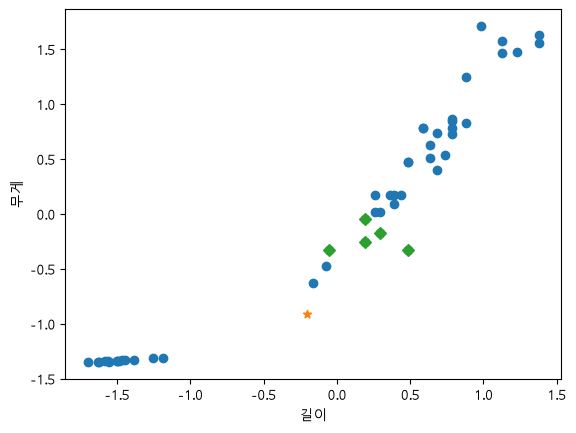

In [84]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

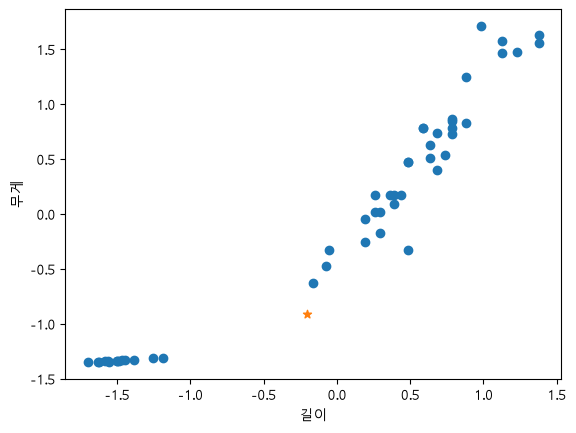

In [85]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [86]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

In [87]:
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data)
score = clf.score(test_data,test_label)
print("예측 : ",score)

예측 :  1.0


In [88]:
# 길이 29.5 무게 330 고기를 분류하시오.  : 도미
# 길이 25, 무게 150 고기를 분류하시오.   : 빙어
# 예측고기 : 도미,빙어
# scatter그래프에 전체 도미,빙어출력, 입력한 2개 고기도 포함해서 출력
# marker='^', '*'

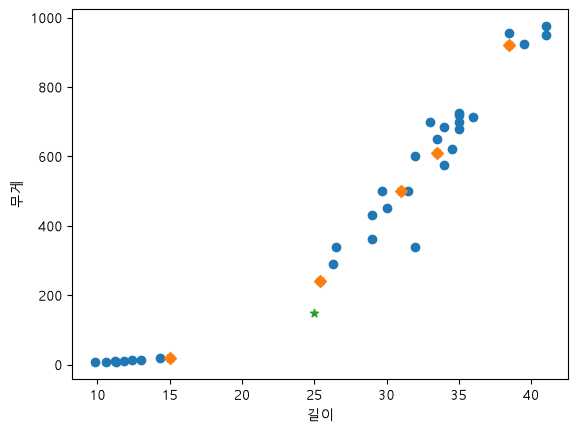

In [89]:
plt.scatter(train_data[:,0],train_data[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
# plt.scatter(29.5,300,marker='^')
plt.scatter(25,150,marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()